# 01 — Dataset Exploration & Data Profiling

        ## Project: Data Quality Detective

        **Dataset:** NYC Yellow Taxi Trip Records — January 2025

        ### Objective

        Explore the original taxi dataset to understand its structure,
        data types, completeness, distributions and potential data-quality
        issues before applying validation and anomaly detection.

        ### Analysis roadmap

        1. Dataset overview
        2. Schema and data types
        3. Missing-value analysis
        4. Duplicate-record analysis
        5. Descriptive statistics
        6. Distribution and outlier analysis
        7. Data-quality observations
        

## 1. Environment Setup

        Import the libraries required for data exploration and visualization.
        

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import pyarrow.parquet as pq

warnings.filterwarnings("ignore", category=FutureWarning)

pd.set_option("display.max_columns", 30)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", lambda value: f"{value:,.3f}")

sns.set_theme(style="whitegrid")

print("Environment setup completed.")

Environment setup completed.


## 2. Load the Original Dataset

        Locate the project root and load the original Parquet file.
        

In [2]:
current_dir = Path.cwd()

if (current_dir / "data").exists():
    PROJECT_ROOT = current_dir
elif (current_dir.parent / "data").exists():
    PROJECT_ROOT = current_dir.parent
else:
    raise FileNotFoundError(
        "Could not locate the project data directory."
    )

DATASET_PATH = (
    PROJECT_ROOT
    / "data"
    / "raw"
    / "nyc_taxi"
    / "yellow_tripdata_2025-01.parquet"
)

if not DATASET_PATH.is_file():
    raise FileNotFoundError(
        f"Dataset not found: {DATASET_PATH}"
    )

df = pd.read_parquet(DATASET_PATH, engine="pyarrow")

print("Dataset loaded successfully.")
print(f"File: {DATASET_PATH.name}")
print(f"Shape: {df.shape[0]:,} rows × {df.shape[1]} columns")
print(f"Memory usage: {df.memory_usage(deep=True).sum() / (1024 ** 2):,.2f} MB")

Dataset loaded successfully.
File: yellow_tripdata_2025-01.parquet
Shape: 3,475,226 rows × 20 columns
Memory usage: 493.47 MB


## 3. Dataset Overview

        Examine the dimensions, sample records and schema.
        

In [3]:
print("Dataset dimensions:", df.shape)

display(df.head())

print("\nColumn names:")
display(pd.Series(df.columns, name="Column"))

print("\nData types:")
display(df.dtypes.rename("Data type").to_frame())

Dataset dimensions: (3475226, 20)


,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,cbd_congestion_fee
0,1,2025-01-01 00:18:38,2025-01-01 00:26:59,1.000,1.600,1.000,N,229,237,1,10.000,3.500,0.500,3.000,0.000,1.000,18.000,2.500,0.000,0.000
1,1,2025-01-01 00:32:40,2025-01-01 00:35:13,1.000,0.500,1.000,N,236,237,1,5.100,3.500,0.500,2.020,0.000,1.000,12.120,2.500,0.000,0.000
2,1,2025-01-01 00:44:04,2025-01-01 00:46:01,1.000,0.600,1.000,N,141,141,1,5.100,3.500,0.500,2.000,0.000,1.000,12.100,2.500,0.000,0.000
3,2,2025-01-01 00:14:27,2025-01-01 00:20:01,3.000,0.520,1.000,N,244,244,2,7.200,1.000,0.500,0.000,0.000,1.000,9.700,0.000,0.000,0.000
4,2,2025-01-01 00:21:34,2025-01-01 00:25:06,3.000,0.660,1.000,N,244,116,2,5.800,1.000,0.500,0.000,0.000,1.000,8.300,0.000,0.000,0.000



Column names:


0                  VendorID
1      tpep_pickup_datetime
2     tpep_dropoff_datetime
3           passenger_count
4             trip_distance
5                RatecodeID
6        store_and_fwd_flag
7              PULocationID
8              DOLocationID
9              payment_type
10              fare_amount
11                    extra
12                  mta_tax
13               tip_amount
14             tolls_amount
15    improvement_surcharge
16             total_amount
17     congestion_surcharge
18              Airport_fee
19       cbd_congestion_fee
Name: Column, dtype: str


Data types:


,Data type
VendorID,int32
tpep_pickup_datetime,datetime64[us]
tpep_dropoff_datetime,datetime64[us]
passenger_count,float64
trip_distance,float64
RatecodeID,float64
store_and_fwd_flag,str
PULocationID,int32
DOLocationID,int32
payment_type,int64


## 4. Initial Observations

        Record factual observations after executing the notebook.
        Do not classify a record as invalid solely because it is unusual;
        validate findings against the dataset's business rules.
        

In [4]:
print("Number of records:", f"{len(df):,}")
print("Number of columns:", len(df.columns))
print("Duplicate column names:", df.columns.duplicated().sum())
print("Exact duplicate rows:", f"{df.duplicated().sum():,}")

print("\nInitial exploration completed.")

Number of records: 3,475,226
Number of columns: 20
Duplicate column names: 0
Exact duplicate rows: 0

Initial exploration completed.


## 5. Missing-Value Analysis

Measure missing values in each column using null counts and percentages.
Identify columns that may require cleaning or special handling.

In [5]:
missing_summary = pd.DataFrame({
    "Missing Count": df.isna().sum(),
    "Missing Percentage": (
        df.isna().sum() / len(df) * 100
    ),
    "Data Type": df.dtypes.astype(str)
})

missing_summary = missing_summary.sort_values(
    by="Missing Count",
    ascending=False
)

display(
    missing_summary.style.format({
        "Missing Count": "{:,.0f}",
        "Missing Percentage": "{:.2f}%"
    })
)

total_missing = int(df.isna().sum().sum())
total_cells = df.shape[0] * df.shape[1]

print(f"Total missing values: {total_missing:,}")
print(f"Total dataset cells: {total_cells:,}")
print(
    f"Overall missing percentage: "
    f"{total_missing / total_cells * 100:.4f}%"
)

,Missing Count,Missing Percentage,Data Type
passenger_count,"540,149",15.54%,float64
congestion_surcharge,"540,149",15.54%,float64
store_and_fwd_flag,"540,149",15.54%,str
RatecodeID,"540,149",15.54%,float64
Airport_fee,"540,149",15.54%,float64
tpep_dropoff_datetime,0,0.00%,datetime64[us]
VendorID,0,0.00%,int32
tpep_pickup_datetime,0,0.00%,datetime64[us]
DOLocationID,0,0.00%,int32
payment_type,0,0.00%,int64


Total missing values: 2,700,745
Total dataset cells: 69,504,520
Overall missing percentage: 3.8857%


In [6]:
display(missing_summary)

,Missing Count,Missing Percentage,Data Type
passenger_count,540149,15.543,float64
congestion_surcharge,540149,15.543,float64
store_and_fwd_flag,540149,15.543,str
RatecodeID,540149,15.543,float64
Airport_fee,540149,15.543,float64
tpep_dropoff_datetime,0,0.000,datetime64[us]
VendorID,0,0.000,int32
tpep_pickup_datetime,0,0.000,datetime64[us]
DOLocationID,0,0.000,int32
payment_type,0,0.000,int64


## 6. Missing-Value Patterns

Investigate whether missing values across the five affected columns
occur in the same taxi records.

In [7]:
missing_columns = missing_summary.index[
    missing_summary["Missing Count"] > 0
].tolist()

missing_pattern = df[missing_columns].isna()

print("Missing columns:", missing_columns)

print("\nMissing values per column:")
display(missing_pattern.sum())

print("\nNumber of rows with all five values missing:",
      f"{missing_pattern.all(axis=1).sum():,}")

print("\nNumber of rows with at least one missing value:",
      f"{missing_pattern.any(axis=1).sum():,}")

print("\nUnique missing-value patterns:")
display(
    missing_pattern.value_counts()
    .rename("Record Count")
    .to_frame()
)

Missing columns: ['passenger_count', 'congestion_surcharge', 'store_and_fwd_flag', 'RatecodeID', 'Airport_fee']

Missing values per column:


passenger_count         540149
congestion_surcharge    540149
store_and_fwd_flag      540149
RatecodeID              540149
Airport_fee             540149
dtype: int64


Number of rows with all five values missing: 540,149

Number of rows with at least one missing value: 540,149

Unique missing-value patterns:


,,,,,Record Count
passenger_count,congestion_surcharge,store_and_fwd_flag,RatecodeID,Airport_fee,
False,False,False,False,False,2935077
True,True,True,True,True,540149


## 7. Missingness by Vendor and Date

Compare records with complete and missing profile fields across
vendors and pickup dates to investigate systematic patterns.

Missingness by Vendor:


,Total_Records,Missing_Records,Missing_Percentage
VendorID,,,
1,753671,88204,11.700
2,2719860,451456,16.600
6,489,489,100.000
7,1206,0,0.000



Daily Missingness Summary:


,Total_Records,Missing_Records,Missing_Percentage
count,33.000,33.000,33.000
mean,"105,309.880","16,368.150",14.050
std,"32,109.900","9,187.010",7.120
min,1.000,0.000,0.000
25%,"93,060.000","10,131.000",10.890
50%,"114,002.000","17,690.000",14.820
75%,"121,966.000","22,851.000",18.690
max,"138,711.000","37,033.000",31.320


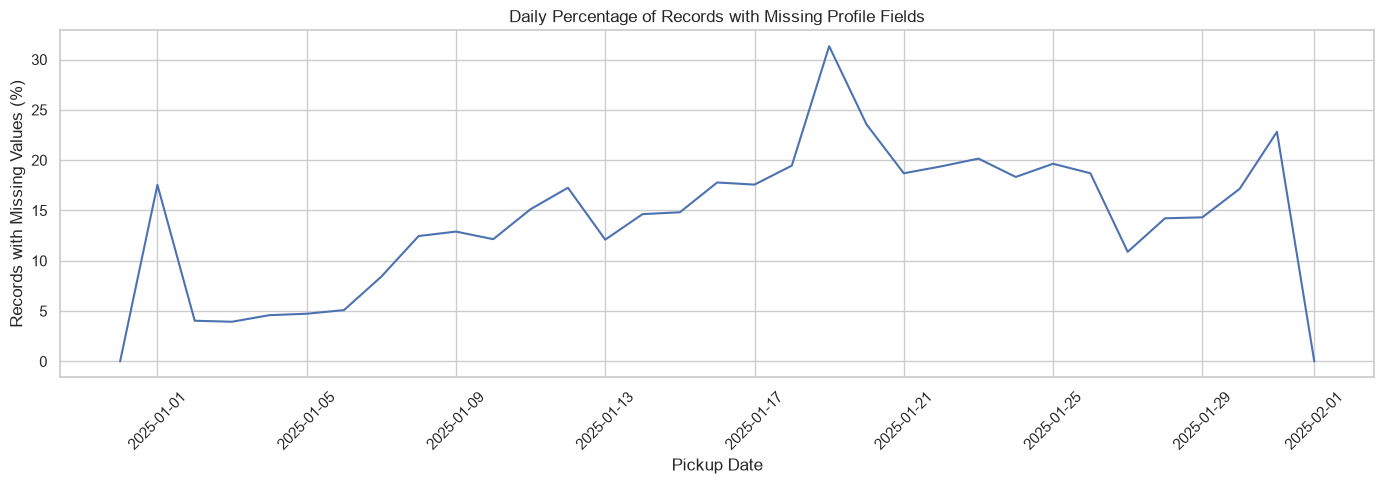

In [8]:
df["has_missing_profile_fields"] = (
    df[missing_columns].isna().all(axis=1)
)

# Missingness by vendor
vendor_missing = (
    df.groupby("VendorID")
    .agg(
        Total_Records=("has_missing_profile_fields", "size"),
        Missing_Records=("has_missing_profile_fields", "sum")
    )
)

vendor_missing["Missing_Percentage"] = (
    vendor_missing["Missing_Records"]
    / vendor_missing["Total_Records"] * 100
)

print("Missingness by Vendor:")
display(vendor_missing.round(2))

# Missingness by pickup date
daily_missing = (
    df.groupby(df["tpep_pickup_datetime"].dt.date)
    .agg(
        Total_Records=("has_missing_profile_fields", "size"),
        Missing_Records=("has_missing_profile_fields", "sum")
    )
)

daily_missing["Missing_Percentage"] = (
    daily_missing["Missing_Records"]
    / daily_missing["Total_Records"] * 100
)

print("\nDaily Missingness Summary:")
display(daily_missing.describe().round(2))

# Plot daily missing percentage
plt.figure(figsize=(14, 5))
plt.plot(
    daily_missing.index,
    daily_missing["Missing_Percentage"]
)
plt.title("Daily Percentage of Records with Missing Profile Fields")
plt.xlabel("Pickup Date")
plt.ylabel("Records with Missing Values (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [9]:
daily_missingness = df.assign(
    pickup_date=df["tpep_pickup_datetime"].dt.date,
    has_missing=df[missing_columns].isna().any(axis=1)
).groupby("pickup_date").agg(
    Total_Records=("has_missing", "size"),
    Missing_Records=("has_missing", "sum")
)

daily_missingness["Missing_Percentage"] = (
    daily_missingness["Missing_Records"]
    / daily_missingness["Total_Records"]
    * 100
)

print("Date range:")
print("First date:", daily_missingness.index.min())
print("Last date:", daily_missingness.index.max())

print("\nAll daily groups, sorted by record count:")
display(
    daily_missingness.sort_values(
        "Total_Records",
        ascending=True
    )
)

print("\nDaily groups with fewer than 100 records:")
display(
    daily_missingness[
        daily_missingness["Total_Records"] < 100
    ]
)

Date range:
First date: 2024-12-31
Last date: 2025-02-01

All daily groups, sorted by record count:


,Total_Records,Missing_Records,Missing_Percentage
pickup_date,,,
2025-02-01,1,0,0.000
2024-12-31,21,0,0.000
2025-01-05,79624,3771,4.736
2025-01-06,80126,4085,5.098
2025-01-02,84832,3427,4.040
2025-01-20,90094,21229,23.563
2025-01-01,90188,15824,17.546
2025-01-03,91250,3595,3.940
2025-01-27,93060,10131,10.887



Daily groups with fewer than 100 records:


,Total_Records,Missing_Records,Missing_Percentage
pickup_date,,,
2024-12-31,21,0,0.000
2025-02-01,1,0,0.000


## 7. Date Boundary Investigation

Inspect records outside the expected January 2025 pickup-date range.
Determine whether these are isolated boundary records.

In [10]:
date_boundary_records = df[
    (df["tpep_pickup_datetime"] < "2025-01-01")
    | (df["tpep_pickup_datetime"] >= "2025-02-01")
]

print(
    "Records outside January 2025:",
    f"{len(date_boundary_records):,}"
)

display(
    date_boundary_records[
        [
            "VendorID",
            "tpep_pickup_datetime",
            "tpep_dropoff_datetime",
            "passenger_count",
            "trip_distance",
            "fare_amount",
            "total_amount"
        ]
    ].sort_values("tpep_pickup_datetime")
)

Records outside January 2025: 22


,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,fare_amount,total_amount
7623,2,2024-12-31 20:47:55,2024-12-31 20:54:00,2.000,1.720,9.300,17.160
17542,2,2024-12-31 20:52:50,2024-12-31 21:09:34,2.000,5.050,23.300,32.300
7624,2,2024-12-31 20:54:50,2024-12-31 21:30:18,2.000,1.390,28.200,39.840
20611,2,2024-12-31 21:15:22,2024-12-31 21:26:00,2.000,3.200,15.600,23.600
7625,2,2024-12-31 21:20:05,2024-12-31 21:35:13,2.000,2.640,16.300,23.300
20612,2,2024-12-31 21:33:43,2024-12-31 21:39:00,2.000,1.120,7.900,10.400
4654,2,2024-12-31 23:24:31,2024-12-31 23:25:35,5.000,0.280,3.700,7.950
4655,2,2024-12-31 23:25:38,2025-01-01 01:01:53,5.000,18.780,70.000,92.500
3941,2,2024-12-31 23:27:13,2024-12-31 23:35:48,1.000,1.530,10.000,18.000
605,2,2024-12-31 23:30:03,2024-12-31 23:43:02,1.000,3.000,16.300,26.620


In [11]:
jan_19 = df[
    df["tpep_pickup_datetime"].dt.date
    == pd.Timestamp("2025-01-19").date()
]

print("January 19 records:", f"{len(jan_19):,}")

display(
    jan_19.groupby("VendorID").agg(
        Total_Records=("VendorID", "size"),
        Missing_Records=(
            "passenger_count",
            lambda x: x.isna().sum()
        )
    )
)

January 19 records: 118,232


,Total_Records,Missing_Records
VendorID,,
1,22782,4032
2,95427,32996
6,5,5
7,18,0


## 8. Duplicate Record Analysis

Investigate exact duplicates and potential duplicate taxi trips
using trip identifiers and selected business attributes.

In [12]:
# Exact duplicate records
exact_duplicates = df.duplicated().sum()

# Duplicate combinations of selected trip attributes
trip_columns = [
    "VendorID",
    "tpep_pickup_datetime",
    "tpep_dropoff_datetime",
    "PULocationID",
    "DOLocationID",
    "trip_distance",
    "fare_amount",
    "total_amount"
]

business_duplicates = df.duplicated(
    subset=trip_columns,
    keep=False
).sum()

print("Exact duplicate rows:", f"{exact_duplicates:,}")
print(
    "Records belonging to duplicate trip-attribute groups:",
    f"{business_duplicates:,}"
)

# Show sample potential duplicate groups
potential_duplicates = df[
    df.duplicated(
        subset=trip_columns,
        keep=False
    )
].sort_values(trip_columns)

display(potential_duplicates.head(20))

Exact duplicate rows: 0
Records belonging to duplicate trip-attribute groups: 0


,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,cbd_congestion_fee,has_missing_profile_fields


## 9. Descriptive Statistics

Examine the distribution of numerical taxi trip attributes.
Identify unusual minimums, maximums, averages and quartiles
that may indicate potential data-quality issues.

In [13]:
numeric_columns = df.select_dtypes(
    include=["number"]
).columns.tolist()

descriptive_stats = df[numeric_columns].describe().T

descriptive_stats["Missing Count"] = (
    df[numeric_columns].isna().sum()
)

display(
    descriptive_stats.style.format("{:,.3f}")
)

,count,mean,std,min,25%,50%,75%,max,Missing Count
VendorID,"3,475,226.000",1.785,0.426,1.000,2.000,2.000,2.000,7.000,0.000
passenger_count,"2,935,077.000",1.298,0.751,0.000,1.000,1.000,1.000,9.000,"540,149.000"
trip_distance,"3,475,226.000",5.855,564.602,0.000,0.980,1.670,3.100,"276,423.570",0.000
RatecodeID,"2,935,077.000",2.483,11.633,1.000,1.000,1.000,1.000,99.000,"540,149.000"
PULocationID,"3,475,226.000",165.192,64.529,1.000,132.000,162.000,234.000,265.000,0.000
DOLocationID,"3,475,226.000",164.125,69.402,1.000,113.000,162.000,234.000,265.000,0.000
payment_type,"3,475,226.000",1.037,0.701,0.000,1.000,1.000,1.000,5.000,0.000
fare_amount,"3,475,226.000",17.082,463.473,-900.000,8.600,12.110,19.500,"863,372.120",0.000
extra,"3,475,226.000",1.318,1.862,-7.500,0.000,0.000,2.500,15.000,0.000
mta_tax,"3,475,226.000",0.478,0.137,-0.500,0.500,0.500,0.500,10.500,0.000


In [14]:
focus_columns = [
    "trip_distance",
    "fare_amount",
    "tip_amount",
    "total_amount",
    "passenger_count"
]

display(
    df[focus_columns].describe(
        percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]
    ).T
)

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
trip_distance,"3,475,226.000",5.855,564.602,0.000,0.000,0.390,0.980,1.670,3.100,11.830,19.500,"276,423.570"
fare_amount,"3,475,226.000",17.082,463.473,-900.000,-10.700,3.700,8.600,12.110,19.500,52.000,72.300,"863,372.120"
tip_amount,"3,475,226.000",2.960,3.780,-86.000,0.000,0.000,0.000,2.450,3.930,10.000,17.190,400.000
total_amount,"3,475,226.000",25.611,463.658,-901.000,-15.700,8.750,15.200,19.950,27.780,74.000,102.920,"863,380.370"
passenger_count,"2,935,077.000",1.298,0.751,0.000,1.000,1.000,1.000,1.000,1.000,3.000,5.000,9.000


## 10. Numerical Anomaly Investigation

Investigate extreme, negative and zero values in trip and
financial attributes. These are screening checks, not final
business-rule violations.

In [15]:
anomaly_checks = {
    "Zero trip distance": df["trip_distance"].eq(0),
    "Negative trip distance": df["trip_distance"].lt(0),
    "Trip distance above 100": df["trip_distance"].gt(100),

    "Negative fare": df["fare_amount"].lt(0),
    "Fare above 500": df["fare_amount"].gt(500),

    "Negative total amount": df["total_amount"].lt(0),
    "Total amount above 500": df["total_amount"].gt(500),

    "Zero passengers": df["passenger_count"].eq(0),
    "Passenger count above 6": df["passenger_count"].gt(6),

    "RatecodeID equal to 99": df["RatecodeID"].eq(99),
    "Payment type equal to 0": df["payment_type"].eq(0),

    "Negative tip": df["tip_amount"].lt(0),
}

anomaly_summary = pd.DataFrame({
    "Check": anomaly_checks.keys(),
    "Record Count": [
        int(condition.sum())
        for condition in anomaly_checks.values()
    ],
})

anomaly_summary["Percentage"] = (
    anomaly_summary["Record Count"] / len(df) * 100
)

display(
    anomaly_summary.style.format({
        "Record Count": "{:,.0f}",
        "Percentage": "{:.4f}%"
    })
)

,Check,Record Count,Percentage
0,Zero trip distance,"90,893",2.6155%
1,Negative trip distance,0,0.0000%
2,Trip distance above 100,162,0.0047%
3,Negative fare,"144,118",4.1470%
4,Fare above 500,55,0.0016%
5,Negative total amount,"63,037",1.8139%
6,Total amount above 500,79,0.0023%
7,Zero passengers,"24,656",0.7095%
8,Passenger count above 6,18,0.0005%
9,RatecodeID equal to 99,"41,963",1.2075%


In [16]:
extreme_records = df.nlargest(
    10,
    "trip_distance"
)[
    [
        "VendorID",
        "tpep_pickup_datetime",
        "tpep_dropoff_datetime",
        "passenger_count",
        "trip_distance",
        "fare_amount",
        "tip_amount",
        "total_amount",
        "payment_type"
    ]
]

display(extreme_records)

,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,fare_amount,tip_amount,total_amount,payment_type
3275762,2,2025-01-22 21:04:00,2025-01-22 21:13:00,NaN,"276,423.570",-4.750,0.000,5.000,0
3188501,2,2025-01-19 14:51:00,2025-01-19 14:58:00,NaN,"276,099.950",9.130,0.000,13.880,0
3240337,2,2025-01-21 09:19:00,2025-01-21 09:45:00,NaN,"222,167.490",31.190,0.000,35.940,0
3112173,2,2025-01-16 10:47:00,2025-01-16 11:11:00,NaN,"206,137.990",24.890,0.000,29.640,0
3374854,2,2025-01-26 17:46:00,2025-01-26 17:59:00,NaN,"202,771.630",10.100,0.000,14.850,0
3081597,2,2025-01-14 19:18:00,2025-01-14 19:36:00,NaN,"189,687.430",12.700,0.000,17.450,0
3069039,2,2025-01-13 21:11:00,2025-01-13 21:17:00,NaN,"181,139.990",6.330,0.000,11.080,0
3312563,2,2025-01-24 08:33:00,2025-01-24 08:44:00,NaN,"168,079.570",-4.000,0.000,4.490,0
3195037,2,2025-01-19 18:31:00,2025-01-19 18:58:00,NaN,"167,452.940",-4.000,0.000,5.450,0
3138510,2,2025-01-17 14:25:00,2025-01-17 14:40:00,NaN,"164,959.950",14.050,0.000,18.050,0


In [17]:
# Create a focused dataset of trips with unusually high distances
extreme_distance_df = df.loc[
    df["trip_distance"] > 100
].copy()

# Calculate trip duration in minutes
extreme_distance_df["trip_duration_minutes"] = (
    extreme_distance_df["tpep_dropoff_datetime"]
    - extreme_distance_df["tpep_pickup_datetime"]
).dt.total_seconds() / 60

# Summary by vendor
display(
    extreme_distance_df.groupby("VendorID").agg(
        record_count=("trip_distance", "size"),
        average_distance=("trip_distance", "mean"),
        minimum_distance=("trip_distance", "min"),
        maximum_distance=("trip_distance", "max"),
        average_duration=("trip_duration_minutes", "mean")
    ).round(2)
)

# Inspect all suspicious records
display(
    extreme_distance_df[
        [
            "VendorID",
            "tpep_pickup_datetime",
            "tpep_dropoff_datetime",
            "trip_duration_minutes",
            "trip_distance",
            "fare_amount",
            "total_amount",
            "passenger_count",
            "payment_type"
        ]
    ].sort_values("trip_distance", ascending=False)
)

,record_count,average_distance,minimum_distance,maximum_distance,average_duration
VendorID,,,,,
1,13,"10,432.880",116.900,"44,730.300",203.040
2,149,"63,480.240",100.170,"276,423.570",54.410


,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,trip_duration_minutes,trip_distance,fare_amount,total_amount,passenger_count,payment_type
3275762,2,2025-01-22 21:04:00,2025-01-22 21:13:00,9.000,"276,423.570",-4.750,5.000,NaN,0
3188501,2,2025-01-19 14:51:00,2025-01-19 14:58:00,7.000,"276,099.950",9.130,13.880,NaN,0
3240337,2,2025-01-21 09:19:00,2025-01-21 09:45:00,26.000,"222,167.490",31.190,35.940,NaN,0
3112173,2,2025-01-16 10:47:00,2025-01-16 11:11:00,24.000,"206,137.990",24.890,29.640,NaN,0
3374854,2,2025-01-26 17:46:00,2025-01-26 17:59:00,13.000,"202,771.630",10.100,14.850,NaN,0
...,...,...,...,...,...,...,...,...,...
1767221,2,2025-01-20 07:30:05,2025-01-20 10:16:55,166.833,102.440,250.000,254.250,1.000,2
2864719,2,2025-01-31 12:32:28,2025-01-31 12:53:16,20.800,102.200,31.700,43.740,1.000,1
509657,2,2025-01-07 10:26:50,2025-01-07 12:10:35,103.750,101.560,410.000,451.810,2.000,1
3445082,2,2025-01-31 00:48:25,2025-01-31 02:52:26,124.017,100.690,300.630,305.380,NaN,0


In [18]:
# Summarize distance and duration distributions
display(
    extreme_distance_df.groupby("VendorID").agg(
        record_count=("trip_distance", "size"),
        median_distance=("trip_distance", "median"),
        average_distance=("trip_distance", "mean"),
        median_duration=("trip_duration_minutes", "median"),
        average_duration=("trip_duration_minutes", "mean"),
        min_duration=("trip_duration_minutes", "min"),
        max_duration=("trip_duration_minutes", "max")
    ).round(2)
)

# Categorize trip distances
distance_bands = pd.cut(
    extreme_distance_df["trip_distance"],
    bins=[100, 200, 500, 1000, 10000, float("inf")],
    labels=["100–200", "200–500", "500–1,000",
            "1,000–10,000", "Above 10,000"],
    right=True
)

display(
    distance_bands.value_counts()
    .sort_index()
    .rename_axis("Distance Range (miles)")
    .reset_index(name="Record Count")
)

# Identify records with unusual durations
duration_checks = {
    "Duration <= 0 minutes":
        extreme_distance_df["trip_duration_minutes"].le(0),
    "Duration under 10 minutes":
        extreme_distance_df["trip_duration_minutes"].lt(10),
    "Duration above 24 hours":
        extreme_distance_df["trip_duration_minutes"].gt(1440),
}

display(pd.DataFrame({
    "Check": duration_checks.keys(),
    "Record Count": [
        int(condition.sum())
        for condition in duration_checks.values()
    ]
}))

,record_count,median_distance,average_distance,median_duration,average_duration,min_duration,max_duration
VendorID,,,,,,,
1,13,181.900,"10,432.880",144.300,203.040,15.800,"1,354.730"
2,149,"67,545.420","63,480.240",20.000,54.410,2.000,"1,578.700"


,Distance Range (miles),Record Count
0,100–200,40
1,200–500,4
2,"500–1,000",2
3,"1,000–10,000",11
4,"Above 10,000",105


,Check,Record Count
0,Duration <= 0 minutes,0
1,Duration under 10 minutes,27
2,Duration above 24 hours,1


## 13. Key Data Profiling Findings

### Missing Data
- 540,149 records (15.54%) contain missing values in five columns: `passenger_count`, `congestion_surcharge`, `store_and_fwd_flag`, `RatecodeID`, and `Airport_fee`.
- Missingness is perfectly aligned across these five columns.
- The same 540,149 records have `payment_type = 0`.
- Vendor 2 contributes the largest number of records with missing values.

### Date Boundaries
- 22 records have pickup dates outside January 2025.
- These records are retained for further investigation rather than automatically deleted.

### Duplicate Records
- No exact duplicate rows were identified.
- No duplicate groups were identified using the selected trip attributes.

### Numerical Anomalies
- 90,893 records have zero trip distance.
- 144,118 records have negative fare amounts.
- 63,037 records have negative total amounts.
- 41,963 records have `RatecodeID = 99`.
- 162 records have trip distances above 100 miles.
- Of these, 105 have distances above 10,000 miles.
- Extreme distances are concentrated in Vendor 2, although Vendor 1 also contains extreme values.

### Preliminary Conclusion

The dataset contains several data-quality concerns, including aligned missing values, unusual payment codes, extreme trip distances, and unusual financial values.

These findings are profiling observations, not confirmed root causes. Records should be flagged and investigated before any cleaning or remediation decisions are made.

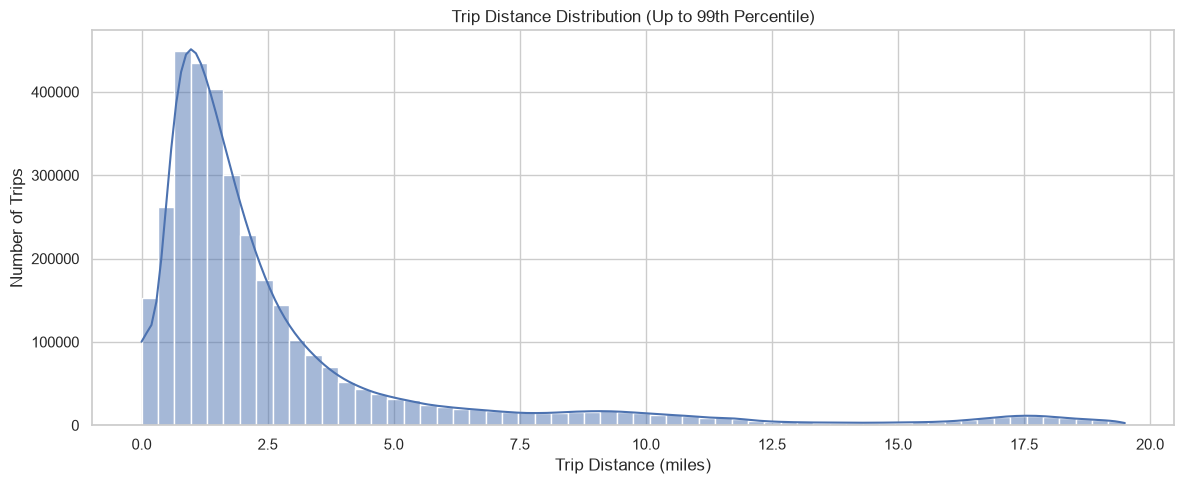

99th percentile: 19.50 miles


In [19]:
# Calculate the 99th percentile
distance_99th = df["trip_distance"].quantile(0.99)

# Plot trip distance distribution
plt.figure(figsize=(12, 5))

sns.histplot(
    df.loc[
        df["trip_distance"].between(0, distance_99th),
        "trip_distance"
    ],
    bins=60,
    kde=True
)

plt.title("Trip Distance Distribution (Up to 99th Percentile)")
plt.xlabel("Trip Distance (miles)")
plt.ylabel("Number of Trips")
plt.tight_layout()
plt.show()

print(f"99th percentile: {distance_99th:.2f} miles")

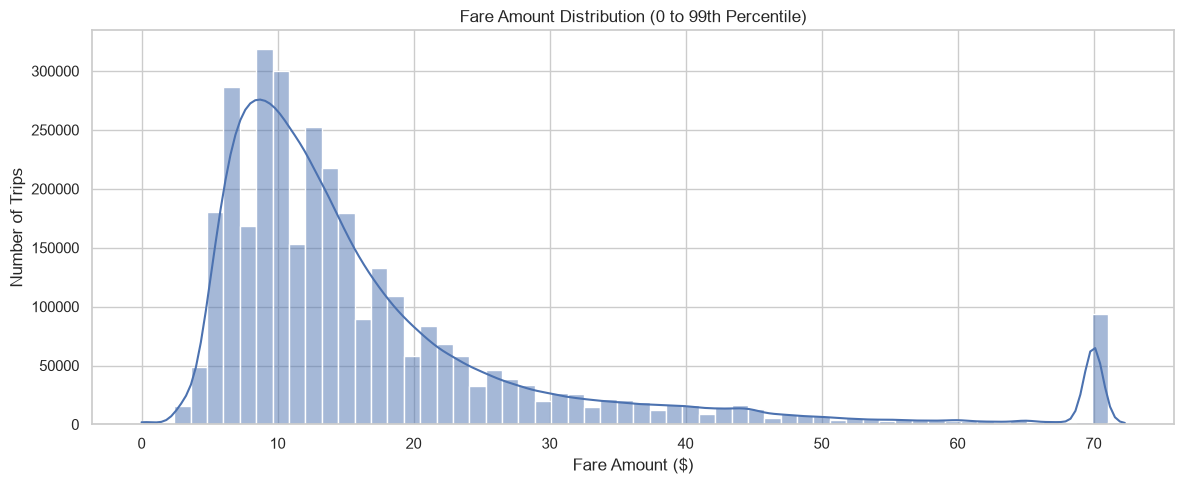

99th percentile fare: $72.30


In [20]:
fare_99th = df["fare_amount"].quantile(0.99)

plt.figure(figsize=(12, 5))

sns.histplot(
    df.loc[
        df["fare_amount"].between(0, fare_99th),
        "fare_amount"
    ],
    bins=60,
    kde=True
)

plt.title("Fare Amount Distribution (0 to 99th Percentile)")
plt.xlabel("Fare Amount ($)")
plt.ylabel("Number of Trips")
plt.tight_layout()
plt.show()

print(f"99th percentile fare: ${fare_99th:.2f}")

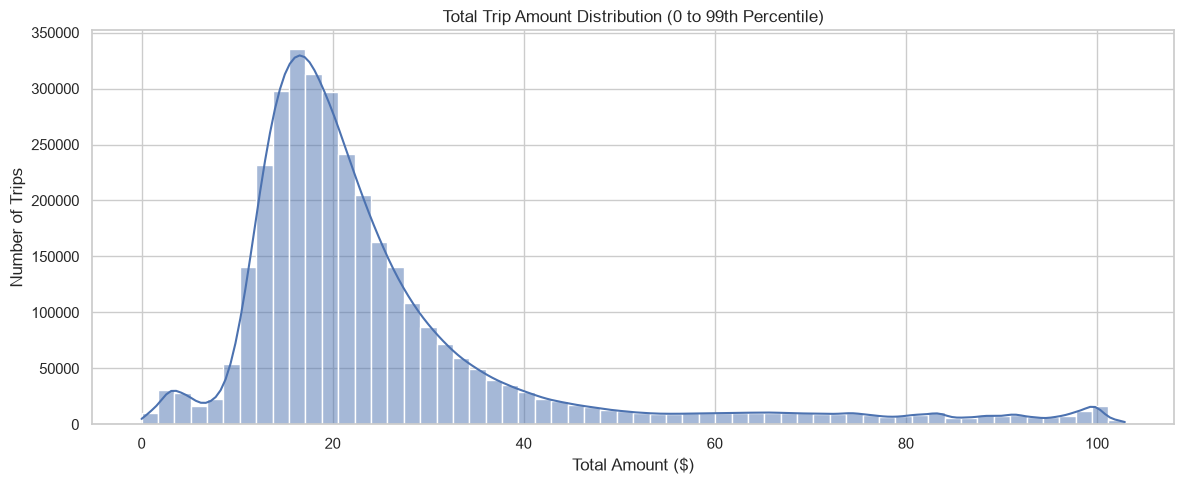

99th percentile total amount: $102.92


In [21]:
total_99th = df["total_amount"].quantile(0.99)

plt.figure(figsize=(12, 5))

sns.histplot(
    df.loc[
        df["total_amount"].between(0, total_99th),
        "total_amount"
    ],
    bins=60,
    kde=True
)

plt.title("Total Trip Amount Distribution (0 to 99th Percentile)")
plt.xlabel("Total Amount ($)")
plt.ylabel("Number of Trips")
plt.tight_layout()
plt.show()

print(f"99th percentile total amount: ${total_99th:.2f}")

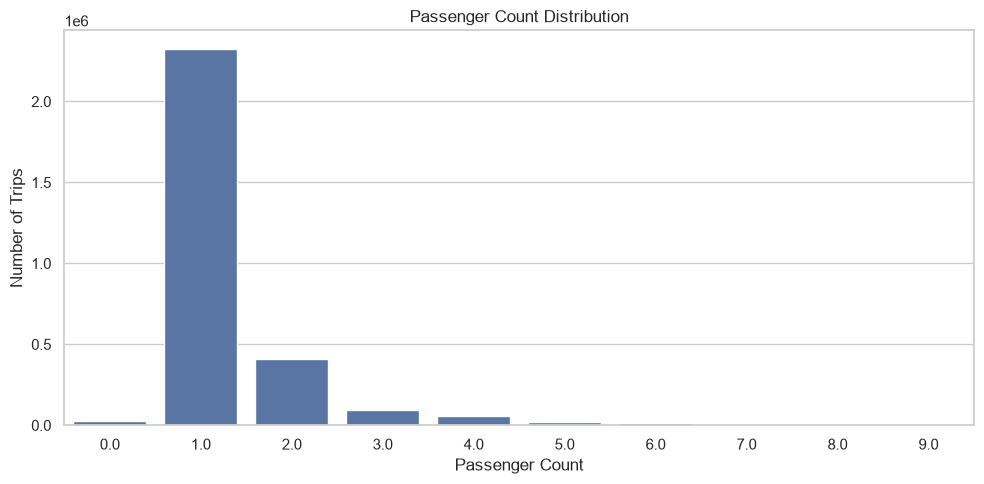

,Passenger Count,Record Count
0,0.000,24656
1,1.000,2322434
2,2.000,407761
3,3.000,91409
4,4.000,59009
5,5.000,17786
6,6.000,12004
7,7.000,4
8,8.000,11
9,9.000,3


In [22]:
plt.figure(figsize=(10, 5))

passenger_counts = (
    df["passenger_count"]
    .value_counts(dropna=False)
    .sort_index()
)

sns.barplot(
    x=passenger_counts.index.astype(str),
    y=passenger_counts.values
)

plt.title("Passenger Count Distribution")
plt.xlabel("Passenger Count")
plt.ylabel("Number of Trips")
plt.tight_layout()
plt.show()

display(
    passenger_counts.rename_axis("Passenger Count")
    .reset_index(name="Record Count")
)

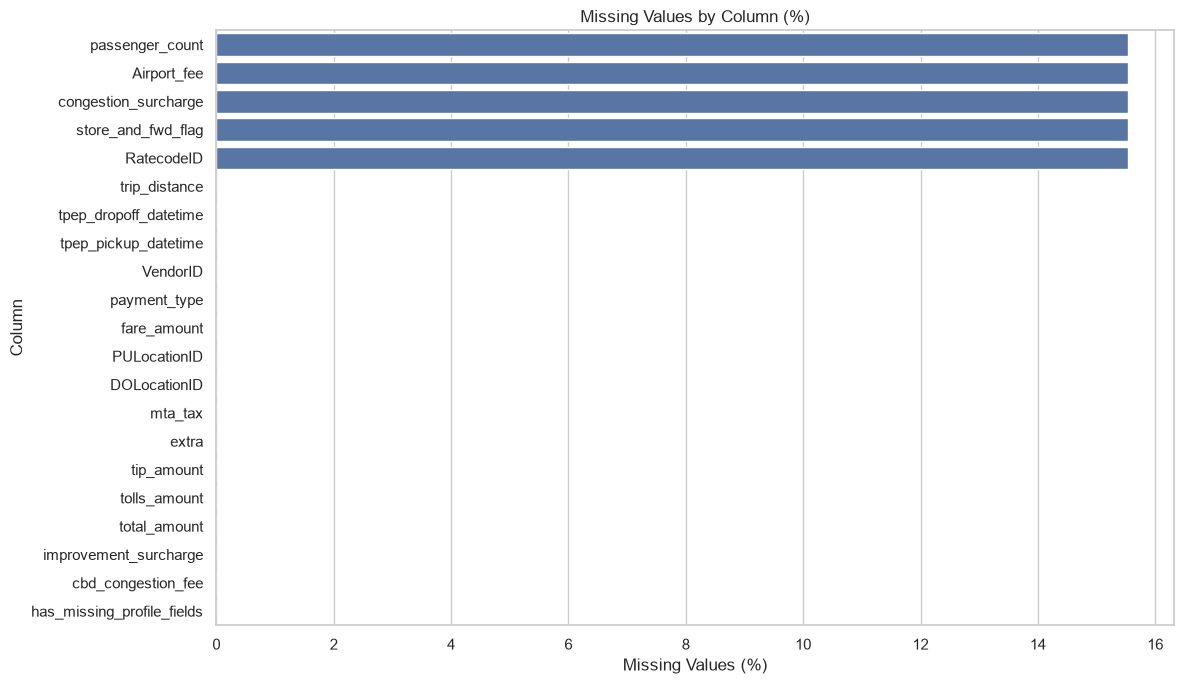

,Missing Percentage
passenger_count,15.54%
Airport_fee,15.54%
congestion_surcharge,15.54%
store_and_fwd_flag,15.54%
RatecodeID,15.54%
trip_distance,0.00%
tpep_dropoff_datetime,0.00%
tpep_pickup_datetime,0.00%
VendorID,0.00%
payment_type,0.00%


In [23]:
missing_percent = (
    df.isnull().mean() * 100
).sort_values(ascending=False)

plt.figure(figsize=(12, 7))

sns.barplot(
    x=missing_percent.values,
    y=missing_percent.index
)

plt.title("Missing Values by Column (%)")
plt.xlabel("Missing Values (%)")
plt.ylabel("Column")
plt.tight_layout()
plt.show()

display(
    missing_percent.rename("Missing Percentage")
    .to_frame()
    .style.format("{:.2f}%")
)

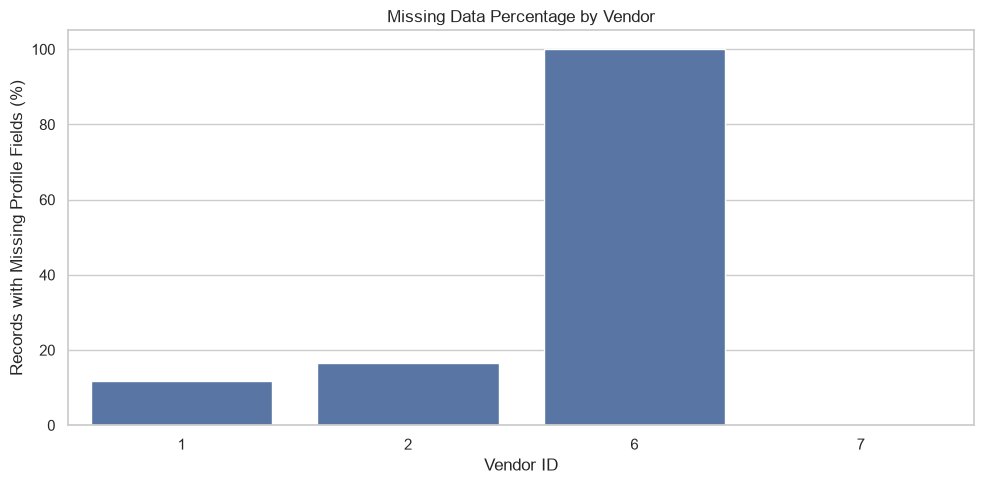

,VendorID,Missing Percentage
0,1,11.70%
1,2,16.60%
2,6,100.00%
3,7,0.00%


In [24]:
vendor_missing = (
    df.groupby("VendorID")
    .apply(
        lambda group: group[
            [
                "passenger_count",
                "congestion_surcharge",
                "store_and_fwd_flag",
                "RatecodeID",
                "Airport_fee"
            ]
        ].isnull().any(axis=1).mean() * 100,
        include_groups=False
    )
    .rename("Missing Percentage")
    .reset_index()
)

plt.figure(figsize=(10, 5))

sns.barplot(
    data=vendor_missing,
    x="VendorID",
    y="Missing Percentage"
)

plt.title("Missing Data Percentage by Vendor")
plt.xlabel("Vendor ID")
plt.ylabel("Records with Missing Profile Fields (%)")
plt.tight_layout()
plt.show()

display(
    vendor_missing.style.format({
        "Missing Percentage": "{:.2f}%"
    })
)

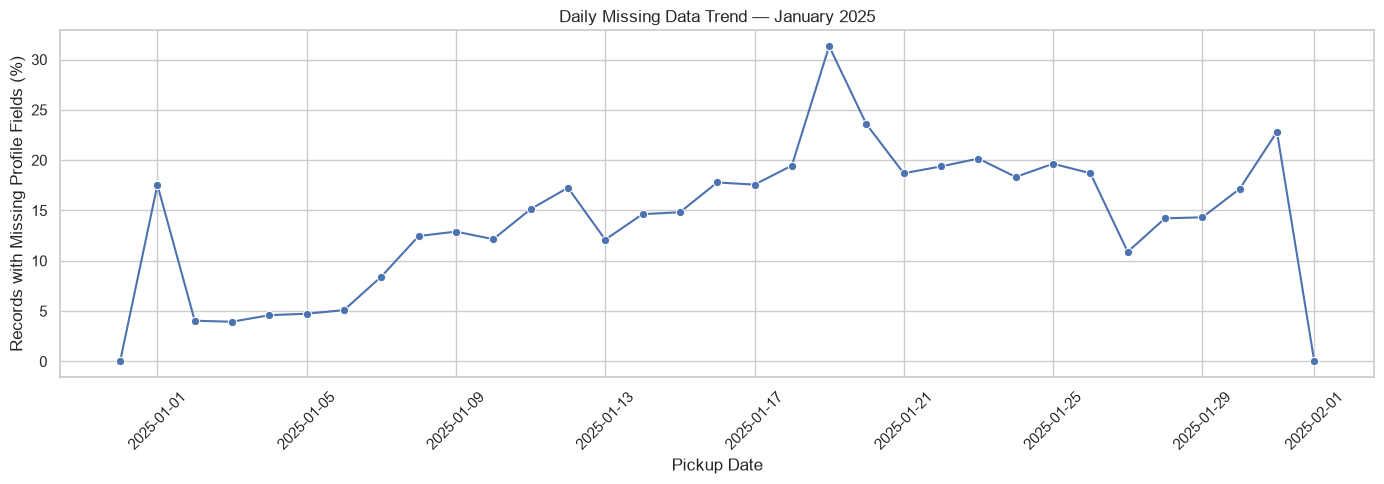

,Pickup Date,Missing Percentage
19,2025-01-19,31.32%
20,2025-01-20,23.56%
31,2025-01-31,22.82%
23,2025-01-23,20.15%
25,2025-01-25,19.64%
18,2025-01-18,19.46%
22,2025-01-22,19.38%
26,2025-01-26,18.70%
21,2025-01-21,18.69%
24,2025-01-24,18.33%


In [25]:
daily_missing = (
    df.groupby(df["tpep_pickup_datetime"].dt.date)
    .apply(
        lambda group: group[
            [
                "passenger_count",
                "congestion_surcharge",
                "store_and_fwd_flag",
                "RatecodeID",
                "Airport_fee"
            ]
        ].isnull().any(axis=1).mean() * 100,
        include_groups=False
    )
    .rename("Missing Percentage")
    .reset_index()
)

daily_missing.columns = [
    "Pickup Date",
    "Missing Percentage"
]

plt.figure(figsize=(14, 5))

sns.lineplot(
    data=daily_missing,
    x="Pickup Date",
    y="Missing Percentage",
    marker="o"
)

plt.title("Daily Missing Data Trend — January 2025")
plt.xlabel("Pickup Date")
plt.ylabel("Records with Missing Profile Fields (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

display(
    daily_missing.sort_values(
        "Missing Percentage",
        ascending=False
    ).head(10).style.format({
        "Missing Percentage": "{:.2f}%"
    })
)

## 15. Visual Data Profiling — Key Findings

### Trip Distance Distribution
- The 99th percentile trip distance is 19.50 miles.
- Most trips are concentrated in relatively short distance ranges.
- Extreme distances significantly distort the overall distribution.

### Fare Amount Distribution
- The 99th percentile fare amount is $72.30.
- The fare distribution has a long upper tail.
- Negative fare values require separate investigation.

### Total Amount Distribution
- The 99th percentile total amount is $102.92.
- Most recorded trip amounts are concentrated below this threshold.
- Extreme financial values affect the overall distribution.

### Passenger Count Distribution
- Single-passenger trips dominate the dataset.
- 540,149 records have missing passenger counts.
- 24,656 records have a passenger count of zero.
- Missing and zero values must be treated as separate conditions.

### Missingness by Column
- Five columns have 15.54% missing values.
- The missing values occur on exactly the same records.
- The other original dataset columns have no missing values.

### Missingness by Vendor
- Vendor 2 has 16.60% missingness.
- Vendor 1 has 11.70% missingness.
- Vendor 6 has 100% missingness across its 489 records.
- Vendor 7 has no missing records.

### Daily Missingness Trend
- January 19 has the highest missingness at 31.32%.
- January 20 follows at 23.56%.
- January 31 has 22.82% missingness.
- Missingness varies considerably across dates.

### Overall Conclusion

Visual profiling confirms that the dataset contains substantial missingness patterns, skewed numerical distributions, extreme trip distances, and vendor- and date-related differences in data completeness.

These findings provide a foundation for subsequent data validation, anomaly detection, root-cause analysis, and remediation.